# Which precinct normalizations preserve the linear mixing model?

2013 and 2016 use **row-max** normalization, because those years' data have no
valid-ballot count. 2019-2025 use **per-ballot** normalization. Comparing the two
periods on real returns mixes the normalization with a large change in the
political landscape. This notebook isolates the normalization with a proof and
with toy data. It needs no election data and no sweep results; everything is
synthetic and seeded.

- **Per-ballot** keeps the linear mixing model (LMM) exact. The abundances are
  voter fractions.
- **Vote-sum** keeps it exact too, but the abundances become vote shares and
  ballot width is lost.
- **Row-max** breaks the sum-to-one LMM whenever the mixed voter types disagree
  on their top candidate. Precincts lie *outside* the simplex of the normalized
  pure types, and no choice of $p$ endmembers fits them exactly. On toy data this
  inflates MVSA's endmembers and gives them negative loadings that the true types
  do not have.

Notation follows Li and Bioucas-Dias (2008), *Minimum volume simplex analysis: a
fast algorithm to unmix hyperspectral data*, IGARSS, pp. III-250-253.

Run time: under a minute (5 MVSA runs on 4000 toy precincts per normalization).

## 1. Setup

**Notation.** Candidates are indexed by $\ell = 1,\dots,L$, voter types
(endmembers) by $i = 1,\dots,p$, and precincts (pixels) by $j = 1,\dots,n$. As in
the MVSA paper, the LMM is

$$
\mathbf Y = \mathbf M \mathbf S \quad \text{s.t.} \quad \mathbf S \succeq 0,\ \ \mathbf 1_p^\top \mathbf S = \mathbf 1_n^\top, \tag{1}
$$

with data $\mathbf Y = [\mathbf y_1,\dots,\mathbf y_n]$, mixing matrix
$\mathbf M = [\mathbf m_1,\dots,\mathbf m_p]$, and abundance matrix
$\mathbf S = [\mathbf s_1,\dots,\mathbf s_n]$. Entry $[\mathbf S]_{ij}$ is the
fraction of endmember $i$ in precinct $j$, so each column $\mathbf s_j$ lies in
the probability simplex
$\Delta_p := \{\mathbf s \in \mathbb R^p : \mathbf s \succeq 0,\ \mathbf 1_p^\top \mathbf s = 1\}$.
The MVSA paper writes (1) in the $p$-dimensional signal subspace, where
$\mathbf M$ is square and $\mathbf Q \equiv \mathbf M^{-1}$. Here we stay in
$\mathbb R^L$, where $\mathbf M$ is $L \times p$. The constraints are the same.
Estimates carry hats: $\hat{\mathbf M}$, $\hat{\mathbf S}$. In the code, `S_hat`
is what `sunsal_mod` returns.

**Generative model.** Precinct $j$ has $B_j$ ballots. A voter of type $i$ marks
candidate $\ell$ with probability $[\mathbf M]_{\ell i} \in [0, 1]$, and
$[\mathbf S]_{ij}$ is the fraction of precinct $j$'s voters of type $i$. Each type
has an expected number of names per ballot $c_i := \mathbf 1_L^\top \mathbf m_i$;
write $\mathbf c = [c_1,\dots,c_p]^\top$. The expected vote matrix
$\mathbf V = [\mathbf v_1,\dots,\mathbf v_n]$ has columns

$$
\underbrace{\mathbf v_j}_{\text{votes}} = \underbrace{B_j}_{\text{ballots}}\ \underbrace{\mathbf M}_{\text{votes/ballot}}\ \underbrace{\mathbf s_j}_{\text{ballots/ballot}}. \tag{2}
$$

**Units.** Two things are counted: a **ballot** (one voter, who casts one ballot)
and a **vote** (one name marked on one ballot). Units appear in gray brackets or
under braces, e.g. $\color{gray}{[\text{votes/ballot}]}$. A bracket with a
subscript, like $[\mathbf M]_{\ell i}$, is still a matrix entry.

| symbol | meaning | units |
|---|---|---|
| $B_j$ | ballots cast in precinct $j$ | ballots |
| $[\mathbf v_j]_\ell$ | votes for candidate $\ell$ in precinct $j$ | votes |
| $[\mathbf M]_{\ell i}$ | chance a type-$i$ ballot marks $\ell$, i.e. votes for $\ell$ per type-$i$ ballot | votes/ballot |
| $[\mathbf S]_{ij}$ | type-$i$ ballots per ballot in precinct $j$ (voter fraction) | ballots/ballot |
| $c_i$ | names per type-$i$ ballot | votes/ballot |
| | a **top vote**: a vote for the precinct's top candidate $\ell^* = \arg\max_\ell [\mathbf v_j]_\ell$ | votes |

Sampling noise is set aside until Section 4. Everything below holds for the
expectation, i.e. in the limit of large $B_j$.

The **abundance sum-to-one constraint (ASC)** $\mathbf 1_p^\top \mathbf S = \mathbf 1_n^\top$
is what matters below. MVSA imposes it
($\mathbf 1_p^\top \mathbf Q \mathbf Y = \mathbf 1_n^\top$), and so does SUNSAL
with `addone="yes"`. If the ASC is dropped, $\mathbf Y = \mathbf M \mathbf S$
with $\mathbf S \succeq 0$ alone is a cone model.

**Normalizations.** Three are in use or under consideration:

| | $\mathbf y_j =$ | units of $\mathbf y_j$ | normalized type $\tilde{\mathbf m}_i$ | abundance = share of ... | width $\mathbf 1_L^\top \mathbf y_j$ |
|---|---|---|---|---|---|
| per-ballot | $\mathbf v_j / B_j$ | votes / ballot | $\mathbf m_i$ [votes / ballot] | ballots (voter fraction) | names per ballot [votes / ballot] |
| vote-sum | $\mathbf v_j / \mathbf 1_L^\top \mathbf v_j$ | votes / vote | $\mathbf m_i / c_i$ [votes / vote] | votes (vote share) | 1 [votes / vote] |
| row-max | $\mathbf v_j / \max_\ell [\mathbf v_j]_\ell$ | votes / top vote | $\mathbf m_i / \max_\ell [\mathbf M]_{\ell i}$ [votes / own-top vote] | none: weights sum to $\Lambda \ge 1$ | votes / top vote |

The last two have the form $\mathbf y = \mathbf v / d(\mathbf v)$, with $d$
positively homogeneous of degree one, $d(\alpha \mathbf v) = \alpha\, d(\mathbf v)$
for $\alpha > 0$. Then $B_j$ cancels:
$\mathbf y_j = \mathbf M \mathbf s_j / d(\mathbf M \mathbf s_j)$.

In the single-precinct statements below we drop the index $j$:
$\mathbf s \in \Delta_p$ is one column of $\mathbf S$, with entries
$s_i := [\mathbf S]_{ij}$.

**Units check.** In ordinary dimensional analysis the vote-sum and row-max ratios
are both dimensionless (votes / votes). What the denominator counts still matters,
because the LMM is a weighted average: $\mathbf y_j = \sum_i [\mathbf S]_{ij} \mathbf m_i$
only adds up if each abundance is a share of the denominator's quantity, and that
quantity is split exactly among the types. Every ballot belongs to exactly one type,
so ballot shares sum to 1. Every vote is cast by exactly one type, so vote shares
sum to 1. Top-candidate votes are not split this way. Each type's profile is
divided by its *own* top candidate $\ell(i)$, while the precinct is divided by the
precinct's top candidate $\ell^*$. Proposition 5 makes this exact.

## 2. Results

**Proposition 1 (per-ballot).**

$$
\underbrace{\mathbf y_j}_{\text{votes/ballot}} = \underbrace{\mathbf M}_{\text{votes/ballot}}\ \underbrace{\mathbf s_j}_{\text{ballots/ballot}},
\qquad
\underbrace{\mathbf 1_L^\top \mathbf y_j}_{\text{votes/ballot}} = \underbrace{\mathbf c^\top}_{\text{votes/ballot}}\ \underbrace{\mathbf s_j}_{\text{ballots/ballot}},
$$

i.e. $\mathbf Y = \mathbf M \mathbf S$. The LMM (1) holds exactly with the true
mixing matrix and with abundances equal to the voter fractions. The width is the
mean number of names per ballot.

*Proof.* Divide (2) by $B_j$. $\square$

**Remark 2 (blank and overvoted ballots).** A ballot that leaves the senate race
blank, or overvotes it (all its senate marks are voided), adds nothing to
$\mathbf v_j$ but is counted in $B_j$. This is a type with $\mathbf m_0 = \mathbf 0$,
so Proposition 1 still holds with $p+1$ types, one at the origin. Such ballots
lower the width. If instead the denominator excludes them,
$\mathbf y_j = \sum_{i \ge 1} \frac{s_i}{1 - s_0} \mathbf m_i$, which is still an
LMM, over voters who cast a counted senate ballot. What matters is that the
denominator *counts voters* and does not depend on how they voted. A denominator
$r_j B_j$ with a precinct-varying factor $r_j$
$\color{gray}{[\text{counted ballots / ballot cast}]}$ gives
$\mathbf 1_p^\top \hat{\mathbf s}_j = 1/r_j$, which violates the ASC: the
abundances are then shares of a quantity that the types do not split exactly. The 2025
`numberOfValidBallot` column is such a case: $r_j$ has median 1.08 and differs by
region.

**Lemma 3 (homogeneous normalizations).** Let $d$ be positively homogeneous with
$d(\mathbf m_i) > 0$. Write $\tilde{\mathbf m}_i := \mathbf m_i / d(\mathbf m_i)$
for the normalized pure types and
$\tilde{\mathbf M} = [\tilde{\mathbf m}_1,\dots,\tilde{\mathbf m}_p]$. Then

$$
\mathbf y = \sum_{i=1}^p w_i(\mathbf s)\, \tilde{\mathbf m}_i, \qquad
w_i(\mathbf s) = \frac{s_i\, d(\mathbf m_i)}{d(\mathbf M \mathbf s)} \ge 0, \qquad
\sum_i w_i(\mathbf s) = \Lambda(\mathbf s) := \frac{\sum_i s_i\, d(\mathbf m_i)}{d\left(\sum_i s_i \mathbf m_i\right)}. \tag{3}
$$

*Proof.*
$\mathbf y = \mathbf M \mathbf s / d(\mathbf M \mathbf s) = \sum_i s_i \mathbf m_i / d(\mathbf M \mathbf s) = \sum_i \frac{s_i d(\mathbf m_i)}{d(\mathbf M \mathbf s)}\, \tilde{\mathbf m}_i$. $\square$

Units: $s_i$ is $\color{gray}{[\text{ballots/ballot}]}$, and $d(\mathbf m_i)$
and $d(\mathbf M \mathbf s)$ are both "$d$-quantity per ballot". So $w_i$ is the
fraction of the precinct's $d$-quantity that type $i$ contributes, *where type
$i$'s contribution is measured with its own $d$*.

So $\mathbf y$ lies in the cone of the $\tilde{\mathbf m}_i$ in every case. It lies
in their *simplex* (the LMM (1) with mixing matrix $\tilde{\mathbf M}$) exactly
when $\Lambda(\mathbf s) = 1$.

**Proposition 4 (vote-sum).** For $d(\mathbf v) = \mathbf 1_L^\top \mathbf v$,
$\Lambda \equiv 1$. The LMM holds exactly with mixing matrix $\tilde{\mathbf M}$,
$\tilde{\mathbf m}_i = \mathbf m_i / c_i$, and abundances

$$
\underbrace{[\hat{\mathbf S}]_{ij}}_{\text{votes/vote}} = \frac{\overbrace{c_i}^{\text{votes/ballot}}\ \overbrace{[\mathbf S]_{ij}}^{\text{ballots/ballot}}}{\underbrace{\mathbf c^\top \mathbf s_j}_{\text{votes/ballot}}},
\qquad
\underbrace{\tilde{\mathbf m}_i}_{\text{votes/vote}} = \frac{\overbrace{\mathbf m_i}^{\text{votes/ballot}}}{\underbrace{c_i}_{\text{votes/ballot}}},
$$

the share of precinct $j$'s *votes* cast by type $i$. The map
$\mathbf s_j \mapsto \hat{\mathbf s}_j$ is a bijection of $\Delta_p$ (inverse
$[\mathbf S]_{ij} \propto [\hat{\mathbf S}]_{ij} / c_i$), but it depends on
$\mathbf c$, which cannot be identified from the data: every $\mathbf y_j$ and
every $\tilde{\mathbf m}_i$ sums to one. Voter fractions and ballot width are
therefore both lost.

*Proof.* $d$ is linear, so
$d(\sum_i s_i \mathbf m_i) = \sum_i s_i d(\mathbf m_i)$ and $\Lambda = 1$ in (3).
Rescaling any $\mathbf m_i$ leaves $\tilde{\mathbf m}_i$, and hence all data,
unchanged, so $\mathbf c$ is not identifiable. $\square$

**Proposition 5 (row-max lies outside the simplex).** Let
$d(\mathbf v) = \max_\ell [\mathbf v]_\ell$ and write $\tilde{\mathbf M}$ for the
row-max-normalized types. Then $\Lambda(\mathbf s) \ge 1$, so

$$
\mathbf y = \Lambda(\mathbf s)\, \bar{\mathbf y}, \qquad
\bar{\mathbf y} := \sum_i \frac{w_i(\mathbf s)}{\Lambda(\mathbf s)} \tilde{\mathbf m}_i \in \operatorname{conv}(\tilde{\mathbf m}_1,\dots,\tilde{\mathbf m}_p).
$$

The precinct sits on the ray through a point of the simplex of the normalized
pure types, a factor $\Lambda \ge 1$ beyond it. Equality $\Lambda(\mathbf s) = 1$
holds iff some candidate $\ell$ is a top candidate of every type present in the
precinct, i.e. $[\mathbf M]_{\ell i} = \max_{\ell'} [\mathbf M]_{\ell' i}$ for all
$i$ with $s_i > 0$.

*Proof.* Let $\ell^*$ be a maximizing index of $\mathbf M \mathbf s$. Then

$$
d(\mathbf M \mathbf s) = \sum_i s_i [\mathbf M]_{\ell^* i} \le \sum_i s_i \max_{\ell'} [\mathbf M]_{\ell' i} = \sum_i s_i\, d(\mathbf m_i),
$$

so $\Lambda \ge 1$. Since $s_i \ge 0$, equality holds iff
$[\mathbf M]_{\ell^* i} = \max_{\ell'} [\mathbf M]_{\ell' i}$ for every $i$ with
$s_i > 0$. If some $\ell$ tops every type present, then
$[\mathbf M \mathbf s]_\ell = \sum_i s_i d(\mathbf m_i)$, which is the largest any
entry of $\mathbf M \mathbf s$ can be. So $\ell$ is a maximizer and equality holds.
This gives the "iff". $\square$

*Units reading of the proof.* Multiply numerator and denominator of $w_i$ by $B_j$:

$$
w_i = \frac{\overbrace{s_i B_j}^{\text{type-}i\text{ ballots}}\ \overbrace{d(\mathbf m_i)}^{\text{votes for }\ell(i)\text{ / type-}i\text{ ballot}}}{\underbrace{B_j\, d(\mathbf M \mathbf s)}_{\text{votes for }\ell^*}}
= \frac{\text{type-}i\text{ votes for its own top candidate } \ell(i)}{\text{all votes for the precinct's top candidate } \ell^*},
$$

$$
\Lambda = \sum_i w_i = \frac{\sum_i \left(\text{type-}i\text{ votes for } \ell(i)\right)}{\sum_i \left(\text{type-}i\text{ votes for } \ell^*\right)} \ \ge\ 1,
$$

because each type votes for its own top candidate at least as often as for
$\ell^*$. The units match (votes / votes), but the numerator counts votes for
different candidates for different types. For vote-sum, the numerator would be
type-$i$ votes for *anyone*, which do partition the denominator, so $\Lambda = 1$.

**Remark 6 (row-max as a stand-in for the voter count).** Row-max is tempting
when there is no ballot count, because its denominator grows with turnout:

$$
\underbrace{\max_\ell [\mathbf v_j]_\ell}_{\text{top votes}} = \underbrace{B_j}_{\text{ballots}}\ \underbrace{f_j}_{\text{top votes/ballot}},
\qquad f_j := \max_\ell [\mathbf M \mathbf s_j]_\ell,
$$

where $f_j$ is the top candidate's share of ballots. Replacing $B_j$ by $B_j f_j$
works only in two steps, each with its own condition.

1. **Exact LMM: one candidate $\ell_0$ tops every voter type**, and therefore
   every precinct. This is the $\Lambda = 1$ case of Proposition 5. The
   denominator is then $[\mathbf v_j]_{\ell_0} = \mathbf e_{\ell_0}^\top \mathbf v_j$,
   a *linear* function of the votes. The proof of Proposition 4 with
   $d = \mathbf e_{\ell_0}^\top$ gives an exact LMM with abundances
   $$
   \underbrace{[\hat{\mathbf S}]_{ij}}_{\text{top votes/top vote}} = \frac{[\mathbf S]_{ij}\, [\mathbf M]_{\ell_0 i}}{[\mathbf M \mathbf s_j]_{\ell_0}},
   $$
   type $i$'s share of $\ell_0$'s votes, not of the voters.
2. **Voter fractions: $f_j$ is also the same in every precinct.** This needs every
   type to mark $\ell_0$ at the same rate, $[\mathbf M]_{\ell_0 i} = f$ for all
   $i$, i.e. a candidate on essentially every ballot. Then the denominator is
   $f B_j$, and Proposition 1 holds up to the constant $f$.

Agreement within each precinct is not enough. If the top candidate differs
between precincts, each precinct is divided by a different linear function, and
the normalized types $\tilde{\mathbf m}_i$ change from precinct to precinct.

In the returns, neither condition holds (notebook 13, *Is row-max a stand-in for
the voter count?*):

| | precincts topped by the national #1 | different top candidates | $f_j$, median (IQR) | corr(row-max denominator, voters) |
|---|---|---|---|---|
| 2013 | 46% (Poe) | 18 | no voter count | no voter count |
| 2016 | 13% (Villanueva); Sotto tops 20% | 26 | no voter count | no voter count |
| 2019 | 42% (Villar) | 30 | 0.60 (0.53-0.66) | 0.83 |
| 2022 | 42% (Padilla) | 32 | 0.54 (0.48-0.60) | 0.76 |
| 2025 | 40% (Go); Aquino tops 35% | 33 | 0.54 (0.46-0.64) | 0.75 |

Without a ballot count, a denominator that is linear in the votes and the same
for every precinct, such as vote-sum (Proposition 4), needs neither condition.
The cost is that abundances become vote shares rather than voter fractions.

Proposition 5 shows that the *true* types do not give a simplex fit. The next
result rules out *any* $p$ endmembers. This matters because MVSA is free to
choose its own.

**Theorem 7 (row-max admits no exact $p$-endmember LMM).** Assume

- (i) $\mathbf M$ has full column rank $p \ge 2$;
- (ii) each type has a unique top candidate $\ell(i) = \arg\max_\ell [\mathbf M]_{\ell i}$;
- (iii) at least two types differ in their top candidate, $\ell(i_1) \ne \ell(i_2)$.

Let
$\mathcal Y = \{\mathbf M \mathbf s / \max_\ell [\mathbf M \mathbf s]_\ell : \mathbf s \in \Delta_p\}$
be the set of row-max-normalized precincts. Then $\mathcal Y$ is not contained in
any affine subspace of dimension $p - 1$. Hence there are no
$\hat{\mathbf M} \in \mathbb R^{L \times p}$ and
$\hat{\mathbf s}(\mathbf s) \in \Delta_p$ with
$\mathbf y(\mathbf s) = \hat{\mathbf M} \hat{\mathbf s}(\mathbf s)$ for all
$\mathbf s$. The same holds for any set of precincts whose columns $\mathbf s_j$
are dense in an open subset of $\Delta_p$ that meets both regions
$R_{\ell(i_1)}$ and $R_{\ell(i_2)}$ defined below.

*Proof.* For a candidate $\ell$, let
$R_\ell = \{\mathbf s \in \operatorname{relint} \Delta_p : [\mathbf M \mathbf s]_\ell > [\mathbf M \mathbf s]_{\ell'}\ \forall \ell' \ne \ell\}$.
It is relatively open, by continuity. By (ii), the vertex $\mathbf e_{i_1}$ has the
strict maximizer $\ell(i_1)$, so points of $\operatorname{relint} \Delta_p$ near
$\mathbf e_{i_1}$ lie in $R_{\ell(i_1)}$, which is therefore nonempty. Likewise
$R_{\ell(i_2)} \ne \emptyset$.

On $R_\ell$,
$\mathbf y(\mathbf s) = \mathbf M \mathbf s / (\mathbf e_\ell^\top \mathbf M \mathbf s)$
is smooth. Its differential along a tangent direction $\boldsymbol\delta$
($\mathbf 1_p^\top \boldsymbol\delta = 0$) is
$D\mathbf y\, \boldsymbol\delta = (\mathbf I - \mathbf y\, \mathbf e_\ell^\top) \mathbf M \boldsymbol\delta / (\mathbf e_\ell^\top \mathbf M \mathbf s)$.
If this vanishes, $\mathbf M \boldsymbol\delta = \alpha \mathbf M \mathbf s$ with
$\alpha = \mathbf e_\ell^\top \mathbf M \boldsymbol\delta / \mathbf e_\ell^\top \mathbf M \mathbf s$.
Then $\boldsymbol\delta = \alpha \mathbf s$ by (i), and
$0 = \mathbf 1_p^\top \boldsymbol\delta = \alpha$, so $\boldsymbol\delta = \mathbf 0$.
The differential is injective, so $\mathbf y(R_\ell)$ contains a
$(p-1)$-dimensional embedded piece and
$\dim \operatorname{aff} \mathbf y(R_\ell) = p - 1$. Every point of
$\mathbf y(R_\ell)$ has $y_\ell = 1$, so
$\operatorname{aff} \mathbf y(R_\ell) \subseteq \{y_\ell = 1\}$.

Write $\ell_1 = \ell(i_1)$ and $\ell_2 = \ell(i_2)$. Suppose
$\mathcal Y \subseteq \mathcal A$ with $\mathcal A$ affine and
$\dim \mathcal A = p - 1$. Then
$\operatorname{aff} \mathbf y(R_{\ell_1}) \subseteq \mathcal A$, and the
dimensions are equal, so
$\mathcal A = \operatorname{aff} \mathbf y(R_{\ell_1}) \subseteq \{y_{\ell_1} = 1\}$.
In the same way $\mathcal A \subseteq \{y_{\ell_2} = 1\}$. But for
$\mathbf s \in R_{\ell_1}$,
$y_{\ell_2}(\mathbf s) = [\mathbf M \mathbf s]_{\ell_2} / [\mathbf M \mathbf s]_{\ell_1} < 1$.
This is a contradiction. Finally, any
$\{\hat{\mathbf M} \hat{\mathbf s} : \hat{\mathbf s} \in \Delta_p\}$ lies in
$\operatorname{aff}(\hat{\mathbf m}_1,\dots,\hat{\mathbf m}_p)$, which has
dimension at most $p - 1$. The dense-subset version follows because the argument
only uses open pieces of $R_{\ell_1}$ and $R_{\ell_2}$. $\square$

**Corollary 8 (what row-max preserves).** Under row-max the cone model is still
exact: $\mathbf y = \tilde{\mathbf M} \mathbf w$ with $\mathbf w \succeq 0$ and
$\mathbf 1_p^\top \mathbf w = \Lambda(\mathbf s) \ge 1$. The failure comes from
the ASC, which both MVSA and SUNSAL (`addone="yes"`) impose. The cone coefficients
are $w_i \propto s_i\, d(\mathbf m_i)$, so voter fractions could be recovered only
if the types' top-candidate rates $d(\mathbf m_i)$ were known.

**Remark 9 (row-max width).** Under row-max,

$$
\underbrace{\mathbf 1_L^\top \mathbf y_j}_{\text{votes / top vote}} = \frac{\overbrace{\mathbf c^\top \mathbf s_j}^{\text{votes/ballot}}}{\underbrace{\max_\ell [\mathbf M \mathbf s_j]_\ell}_{\text{top votes/ballot}}}:
$$

names per ballot divided by the top candidate's share of ballots. This quantity
varies with both ballot width and how concentrated the vote is on one candidate.
$\Lambda(\mathbf s) - 1$ is largest where the mixed types disagree about the top
candidate. So a "width" archetype under row-max partly encodes disagreement over
the top candidate. On the real 2019-2025 data, row-max width correlates with
names per ballot at only 0.68, 0.73 and 0.40 (see notebook 13).

## 3. Toy data: setup

In [1]:
import sys
import warnings

sys.path.append("..")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

from src.unmixing import extract_endmembers, sunsal_mod

# VCA prints these on every run; they do not affect the result
warnings.filterwarnings("ignore", message="sparse_svds failed")
warnings.filterwarnings("ignore", message="SNR estimation")

# Colours from the dataviz reference palette: categorical slots 1-3 (one per normalization), ink, grid
NORMS = ["ballot", "sum", "rowmax"]
LABEL = {"ballot": "per-ballot", "sum": "vote-sum", "rowmax": "row-max"}
UNITS = {"ballot": "votes / ballot", "sum": "votes / vote", "rowmax": "votes / top vote"}
COLOR = {"ballot": "#2a78d6", "sum": "#eb6834", "rowmax": "#1baf7a"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

mpl.rcParams.update({
    "font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 120,
})


def normalize(V, kind, B=None):
    """Column-wise normalization of an (L, n) count (or expected-count) matrix."""
    if kind == "ballot":
        return V / B
    if kind == "sum":
        return V / V.sum(axis=0)
    if kind == "rowmax":
        return V / V.max(axis=0)
    raise ValueError(kind)


def fit_abundances(M, Y, asc=True):
    """S_hat >= 0 (and 1_p^T S_hat = 1_n^T if asc) by SUNSAL, for fixed M."""
    S_hat, _, _ = sunsal_mod(M, Y, positivity="yes", addone="yes" if asc else "no",
                             AL_iters=3000, tol=1e-8)
    return S_hat


def solid_legend(leg):
    for h in getattr(leg, "legend_handles", None) or leg.legendHandles:
        h.set_alpha(1)

### Two candidates, two voter types

With $L = p = 2$ the three normalizations can be drawn directly. Per-ballot data
lie on the segment between the two profiles, evenly spaced in
$t = [\mathbf S]_{2j}$. Vote-sum data lie on the segment between the normalized
profiles, on the line $y_1 + y_2 = 1$, but unevenly spaced: the abundance is
$[\hat{\mathbf S}]_{2j} = c_2 t / (c_1(1-t) + c_2 t)$, not $t$. Row-max data
follow the boundary of the unit square through $(1, 1)$. They bulge past the
segment by the factor $\Lambda$ (Proposition 5). No single segment, i.e. no
2-endmember LMM, contains them (Theorem 7).

Type profiles $\mathbf m_1 = (0.80, 0.35)$ and $\mathbf m_2 = (0.30, 0.60)$ have
different top candidates. Squares mark the normalized pure types.

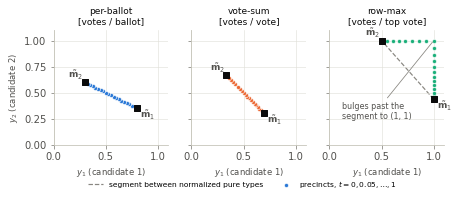

In [2]:
M2 = np.array([[0.80, 0.30],
               [0.35, 0.60]])  # columns m_1, m_2
t = np.linspace(0, 1, 21)  # [S]_{2j}: fraction of type-2 voters
S2 = np.vstack([1 - t, t])
V2 = M2 @ S2  # expected names per ballot = V / B (B cancels)

fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.6), sharex=True, sharey=True)
for ax, kind in zip(axes, NORMS):
    Y = normalize(V2, kind, B=1.0)
    M_tilde = normalize(M2, kind, B=1.0)  # normalized pure types
    ax.plot(M_tilde[0], M_tilde[1], ls="--", lw=1.2, color=MUTED, zorder=1,
            label="segment between normalized pure types")
    ax.scatter(Y[0], Y[1], s=16, color=COLOR[kind], edgecolor="white", linewidth=0.6,
               zorder=3, label="precincts, $t=0,0.05,\\ldots,1$")
    ax.scatter(M_tilde[0], M_tilde[1], s=36, marker="s", color=INK, zorder=4)
    for i, (dx, dy) in enumerate([(0.03, -0.09), (-0.16, 0.04)]):
        ax.annotate(f"$\\tilde{{\\mathbf{{m}}}}_{i + 1}$", (M_tilde[0, i], M_tilde[1, i]),
                    (M_tilde[0, i] + dx, M_tilde[1, i] + dy), color=INK2, fontsize=9)
    if kind == "rowmax":
        ax.annotate("bulges past the\nsegment to (1, 1)", (1, 1), (0.12, 0.25),
                    color=INK2, fontsize=8, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    ax.set(title=f"{LABEL[kind]}\n[{UNITS[kind]}]", xlim=(0, 1.1), ylim=(0, 1.1), aspect="equal",
           xlabel="$y_1$ (candidate 1)")
axes[0].set_ylabel("$y_2$ (candidate 2)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=7.5, bbox_to_anchor=(0.5, -0.08))
plt.show()

### Twelve candidates, three voter types

Type 1 votes a wide slate ($c_1 = 5.6$ names per ballot, top candidate 1). Type 2
is medium ($c_2 = 3.7$, top candidate 9). Type 3 is narrow ($c_3 = 2.25$, top
candidate 12). Every other candidate gets probability 0.05. Precincts:
$n = 4000$, $\mathbf s_j \sim \mathrm{Dirichlet}(0.7, 0.7, 0.7)$,
$B_j \sim \mathrm{Unif}\{200,\dots,799\}$.

In [3]:
L, p, n = 12, 3, 4000
M = np.full((L, p), 0.05)  # [M]_{li}: chance a type-i voter marks candidate l
M[[0, 1, 2, 3, 4, 5, 6, 7], 0] = [0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.55, 0.50]  # wide slate
M[[3, 4, 8, 9, 10, 2], 1] = [0.50, 0.45, 0.90, 0.60, 0.55, 0.40]
M[[5, 6, 10, 11], 2] = [0.35, 0.30, 0.40, 0.80]  # narrow slate
TOPS = M.argmax(axis=0)

rng = np.random.default_rng(0)
S = rng.dirichlet([0.7] * p, n).T  # (p, n) voter-type fractions
B = rng.integers(200, 800, n)  # ballots per precinct

# Lambda(s_j) for row-max: sum_i s_i max_l [M]_{li} / max_l [M s_j]_l
LAM = (M.max(axis=0) @ S) / (M @ S).max(axis=0)

print("widths c_i:", M.sum(axis=0).round(2), " top candidates:", TOPS + 1)
print("Lambda: median %.3f, 95th pct %.3f, max %.3f" % tuple(np.percentile(LAM, [50, 95, 100])))

widths c_i: [5.6  3.7  2.25]  top candidates: [ 1  9 12]
Lambda: median 1.481, 95th pct 2.033, max 2.310


## 4. Noise-free, true endmembers known

Fit abundances with SUNSAL (non-negative, with the ASC) using the true
normalized endmembers $\tilde{\mathbf M}$. Per-ballot should recover $\mathbf S$
exactly. Vote-sum should recover the vote-share reweighting of Proposition 4,
also with zero residual. The reweighting depends on all of $\mathbf s_j$ through
$\mathbf c^\top \mathbf s_j$, so it plots as a band rather than a curve.
Row-max should leave a residual that grows with $\Lambda - 1$, and dropping the
ASC should bring it back to zero (Corollary 8).

In [4]:
MS = M @ S  # expected names per ballot (noise-free data, B cancels)
fit = {}
for kind in NORMS:
    Y = normalize(MS, kind, B=1.0)
    M_tilde = normalize(M, kind, B=1.0)
    S_hat = fit_abundances(M_tilde, Y)
    S_cone = fit_abundances(M_tilde, Y, asc=False)
    fit[kind] = {
        "S_hat": S_hat,
        "res": np.linalg.norm(Y - M_tilde @ S_hat, axis=0),
        "res_cone": np.linalg.norm(Y - M_tilde @ S_cone, axis=0),
    }

pd.DataFrame({
    "max residual, with ASC": {LABEL[k]: fit[k]["res"].max() for k in NORMS},
    "max residual, no ASC": {LABEL[k]: fit[k]["res_cone"].max() for k in NORMS},
}).style.format("{:.2e}")

,"max residual, with ASC","max residual, no ASC"
per-ballot,1.74e-07,1.08e-07
vote-sum,2.59e-08,1.96e-08
row-max,1.48e+00,2.99e-07


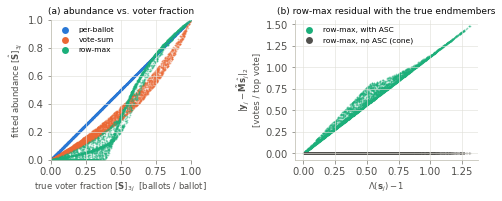

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.0, 2.9))
I = 2  # the narrow-slate type: largest reweighting under vote-sum
ax1.plot([0, 1], [0, 1], color=AXIS, lw=0.8, zorder=1)
for kind in NORMS:
    ax1.scatter(S[I], fit[kind]["S_hat"][I], s=3, color=COLOR[kind], alpha=0.5, lw=0,
                label=LABEL[kind], rasterized=True)
ax1.set(xlabel=f"true voter fraction $[\\mathbf{{S}}]_{{{I + 1}j}}$  [ballots / ballot]",
        ylabel=f"fitted abundance $[\\hat{{\\mathbf{{S}}}}]_{{{I + 1}j}}$",
        xlim=(0, 1), ylim=(0, 1), aspect="equal", title="(a) abundance vs. voter fraction")
solid_legend(ax1.legend(loc="upper left", markerscale=4, fontsize=7.5))

ax2.scatter(LAM - 1, fit["rowmax"]["res"], s=3, color=COLOR["rowmax"], alpha=0.5, lw=0,
            rasterized=True, label="row-max, with ASC")
ax2.scatter(LAM - 1, fit["rowmax"]["res_cone"], s=3, color=INK2, alpha=0.5, lw=0,
            rasterized=True, label="row-max, no ASC (cone)")
ax2.set(xlabel="$\\Lambda(\\mathbf{s}_j) - 1$",
        ylabel="$\\|\\mathbf{y}_j - \\tilde{\\mathbf{M}}\\hat{\\mathbf{s}}_j\\|_2$\n[votes / top vote]",
        title="(b) row-max residual with the true endmembers")
solid_legend(ax2.legend(loc="upper left", markerscale=4, fontsize=7.5))
fig.tight_layout(w_pad=2.5)
plt.show()

## 5. Blind MVSA on noisy counts

Counts $[\mathbf V]_{\ell j} \sim \mathrm{Binomial}(B_j, [\mathbf M \mathbf s_j]_\ell)$
go through each normalization, then the pipeline's MVSA (`extract_endmembers`,
$p = 3$, best of 5 seeds by RMSE) and SUNSAL. The *noise floor* is the RMSE of
the cone fit with the true endmembers: what sampling noise alone costs. RMSEs are
divided by it because the normalizations put the data on different scales. For
the same reason, the minimum loading and the negative-loading count (loadings
below −1%) are relative to the largest true loading.

In [6]:
V = rng.binomial(np.broadcast_to(B, (L, n)), np.clip(MS, 0, 1))  # (L, n) vote counts
rows, recov = [], {}
for kind in NORMS:
    Y = normalize(V, kind, B=B)
    M_tilde = normalize(M, kind, B=1.0)
    rmse_true = np.sqrt(np.mean((Y - M_tilde @ fit_abundances(M_tilde, Y)) ** 2))
    rmse_cone = np.sqrt(np.mean((Y - M_tilde @ fit_abundances(M_tilde, Y, asc=False)) ** 2))
    runs = []
    for seed in range(5):
        M_hat = extract_endmembers(Y, p, seed, "mvsa", {"MM_iters": 10})
        S_hat = fit_abundances(M_hat, Y)
        runs.append((np.sqrt(np.mean((Y - M_hat @ S_hat) ** 2)), M_hat, S_hat))
    rmse, M_hat, S_hat = min(runs, key=lambda r: r[0])
    cos = (M_tilde / np.linalg.norm(M_tilde, axis=0)).T @ (M_hat / np.linalg.norm(M_hat, axis=0))
    _, perm = linear_sum_assignment(-cos)
    M_hat, S_hat = M_hat[:, perm], S_hat[perm]
    recov[kind] = (M_tilde, M_hat)
    rows.append({
        "normalization": LABEL[kind],
        "RMSE / floor, true M_tilde": rmse_true / rmse_cone,
        "RMSE / floor, MVSA": rmse / rmse_cone,
        "noise floor (RMSE)": rmse_cone,
        "min loading (% of max true)": 100 * M_hat.min() / M_tilde.max(),
        "# negative (< -1%)": int((M_hat < -0.01 * M_tilde.max()).sum()),
        "MVSA column sums": "/".join(f"{v:.2f}" for v in M_hat.sum(axis=0)),
        "true column sums": "/".join(f"{v:.2f}" for v in M_tilde.sum(axis=0)),
    })
mvsa_table = pd.DataFrame(rows).set_index("normalization")
mvsa_table.round(4)

,"RMSE / floor, true M_tilde","RMSE / floor, MVSA",noise floor (RMSE),min loading (% of max true),# negative (< -1%),MVSA column sums,true column sums
normalization,,,,,,,
per-ballot,1.0533,1.0513,0.0180,1.6302,0,5.76/3.67/2.14,5.60/3.70/2.25
vote-sum,1.0018,0.9996,0.0049,-7.1330,4,1.00/1.00/1.00,1.00/1.00/1.00
row-max,6.0220,3.0254,0.0325,-16.7627,4,10.01/6.52/3.61,6.59/4.11/2.81


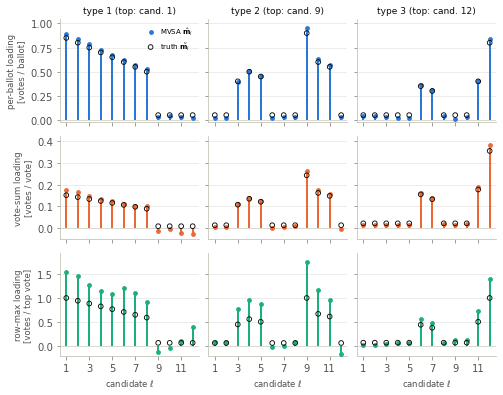

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(7.0, 5.6), sharex=True)
x = np.arange(1, L + 1)
for r, kind in enumerate(NORMS):
    M_tilde, M_hat = recov[kind]
    lo = min(M_hat.min(), 0) * 1.15 - 0.02
    hi = max(M_hat.max(), M_tilde.max()) * 1.1
    for i in range(p):
        ax = axes[r, i]
        ax.axhline(0, color=AXIS, lw=0.8, zorder=1)
        ax.vlines(x, 0, M_hat[:, i], color=COLOR[kind], lw=2, zorder=2)
        ax.scatter(x, M_hat[:, i], s=14, color=COLOR[kind], zorder=3,
                   label="MVSA $\\hat{\\mathbf{m}}_i$" if (r, i) == (0, 0) else None)
        ax.scatter(x, M_tilde[:, i], s=22, facecolor="none", edgecolor=INK, lw=0.9, zorder=4,
                   label="truth $\\tilde{\\mathbf{m}}_i$" if (r, i) == (0, 0) else None)
        ax.set_ylim(lo, hi)
        if r == 0:
            ax.set_title(f"type {i + 1} (top: cand. {TOPS[i] + 1})")
        if i == 0:
            ax.set_ylabel(f"{LABEL[kind]} loading\n[{UNITS[kind]}]")
        else:
            ax.tick_params(labelleft=False)
        ax.grid(axis="x", visible=False)
for ax in axes[-1]:
    ax.set_xticks(x[::2])
    ax.set_xlabel("candidate $\\ell$")
axes[0, 0].legend(loc="upper right", fontsize=7, handletextpad=0.3)
fig.tight_layout(h_pad=1.0, w_pad=0.6)
plt.show()

## Summary

Numbers from the run above (seeded, so they are the same on every rerun).

- **Noise-free, true endmembers:** per-ballot and vote-sum residuals are zero to
  solver tolerance. Row-max residual reaches 1.48 and grows with $\Lambda - 1$
  (median $\Lambda$ = 1.48, max 2.31). Dropping the ASC brings it back to zero.
- **Blind MVSA, noisy counts:**
  - *Per-ballot* recovers the profiles and their widths (column sums
    5.76/3.67/2.14 vs. 5.60/3.70/2.25), with no negative loadings and RMSE at the
    floor.
  - *Vote-sum* also fits at the floor. Its 4 small negatives (down to −7%) sit
    where the true loadings are near zero ($0.05/c_i$) and come from noise.
  - *Row-max* is 3.0× the floor even with MVSA choosing its own endmembers. It
    inflates the column sums by 28-59% (10.01/6.52/3.61 vs. 6.59/4.11/2.81) and
    produces negative loadings down to −17% of the largest true loading. The true
    profiles have no negative loadings.

**What this means for the election data**

1. Per-ballot normalization is the only one of the three whose abundances are
   voter fractions and whose endmember column sums are names per ballot
   (Proposition 1). This requires a denominator that counts voters. For 2025 that
   means `numberOfActuallyVoters`, not `numberOfValidBallot` (Remark 2).
2. Row-max does not just rescale the per-ballot results. Wherever the mixed
   groups disagree on the top candidate, it moves precincts off the simplex
   (Proposition 5), and no set of $p$ endmembers can bring them all back
   (Theorem 7). Some of the 2013/2016 negative loadings may therefore come from
   the normalization. The 2019-2025 mostly-negative archetype cannot be explained
   this way, because those years are per-ballot.
3. Switching every year to row-max would make the years comparable in
   normalization, but by applying this distortion to all of them. A cleaner check
   is to run 2019-2025 under both per-ballot and row-max. Political change is held
   fixed there, so any difference measures the normalization effect directly.